
# BCCD: подсчёт клеток и OOD-детекция


In [ ]:

!pip install ultralytics -q


## Импорты

In [1]:

import os
import cv2
import glob
import torch
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score

from torchvision import models, transforms
from torch import nn
from torch.utils.data import Dataset, DataLoader
from PIL import Image

from ultralytics import YOLO


In [ ]:
from IPython.display import display


## Пути к датасету

In [2]:
IMG_DIR = 'BCCD_Dataset-master/BCCD/JPEGImages'
ANN_DIR = 'BCCD_Dataset-master/BCCD/Annotations'


## Анализ датасета

In [3]:

images = glob.glob(os.path.join(IMG_DIR, '*.jpg'))
print('Количество изображений:', len(images))

sample = cv2.imread(images[0])
print('Размер изображения:', sample.shape)


Количество изображений: 364
Размер изображения: (480, 640, 3)


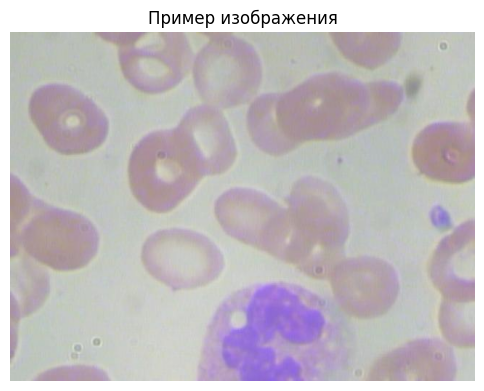

In [4]:

sample_img = cv2.cvtColor(cv2.imread(images[0]), cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6,6))
plt.imshow(sample_img)
plt.title('Пример изображения')
plt.axis('off')
plt.show()


### Доп сводка и визуализации


In [8]:

import xml.etree.ElementTree as ET

records = []

for xml_file in glob.glob(os.path.join(ANN_DIR, '*.xml')):
    tree = ET.parse(xml_file)
    root = tree.getroot()

    counts = {'RBC':0, 'WBC':0, 'Platelets':0}

    for obj in root.findall('object'):
        cls = obj.find('name').text
        if cls in counts:
            counts[cls] += 1

    filename = root.find('filename').text

    records.append({
        'image': os.path.join(IMG_DIR, filename),
        'RBC': counts['RBC'],
        'WBC': counts['WBC'],
        'Platelets': counts['Platelets']
    })

df = pd.DataFrame(records)
df.head()


,image,RBC,WBC,Platelets
0,BCCD_Dataset-master/BCCD/JPEGImages/BloodImage...,10,1,1
1,BCCD_Dataset-master/BCCD/JPEGImages/BloodImage...,13,1,1
2,BCCD_Dataset-master/BCCD/JPEGImages/BloodImage...,10,1,2
3,BCCD_Dataset-master/BCCD/JPEGImages/BloodImage...,16,1,1
4,BCCD_Dataset-master/BCCD/JPEGImages/BloodImage...,10,1,2


,count,mean,std,min,25%,50%,75%,max
RBC,364.0,11.414835,4.267360,0.0,9.0,11.0,14.0,27.0
WBC,364.0,1.021978,0.233692,0.0,1.0,1.0,1.0,2.0
Platelets,364.0,0.991758,1.151087,0.0,0.0,1.0,2.0,6.0


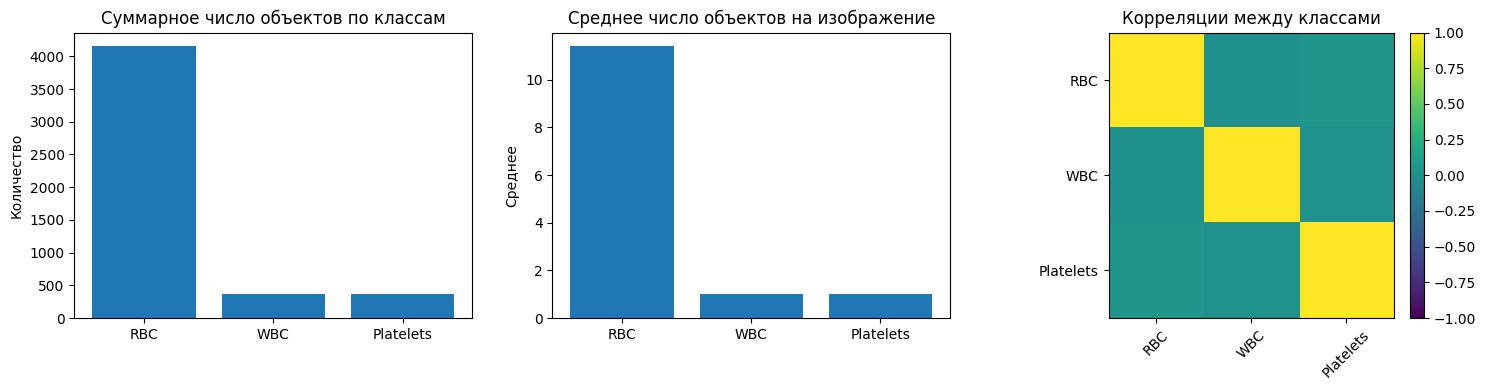

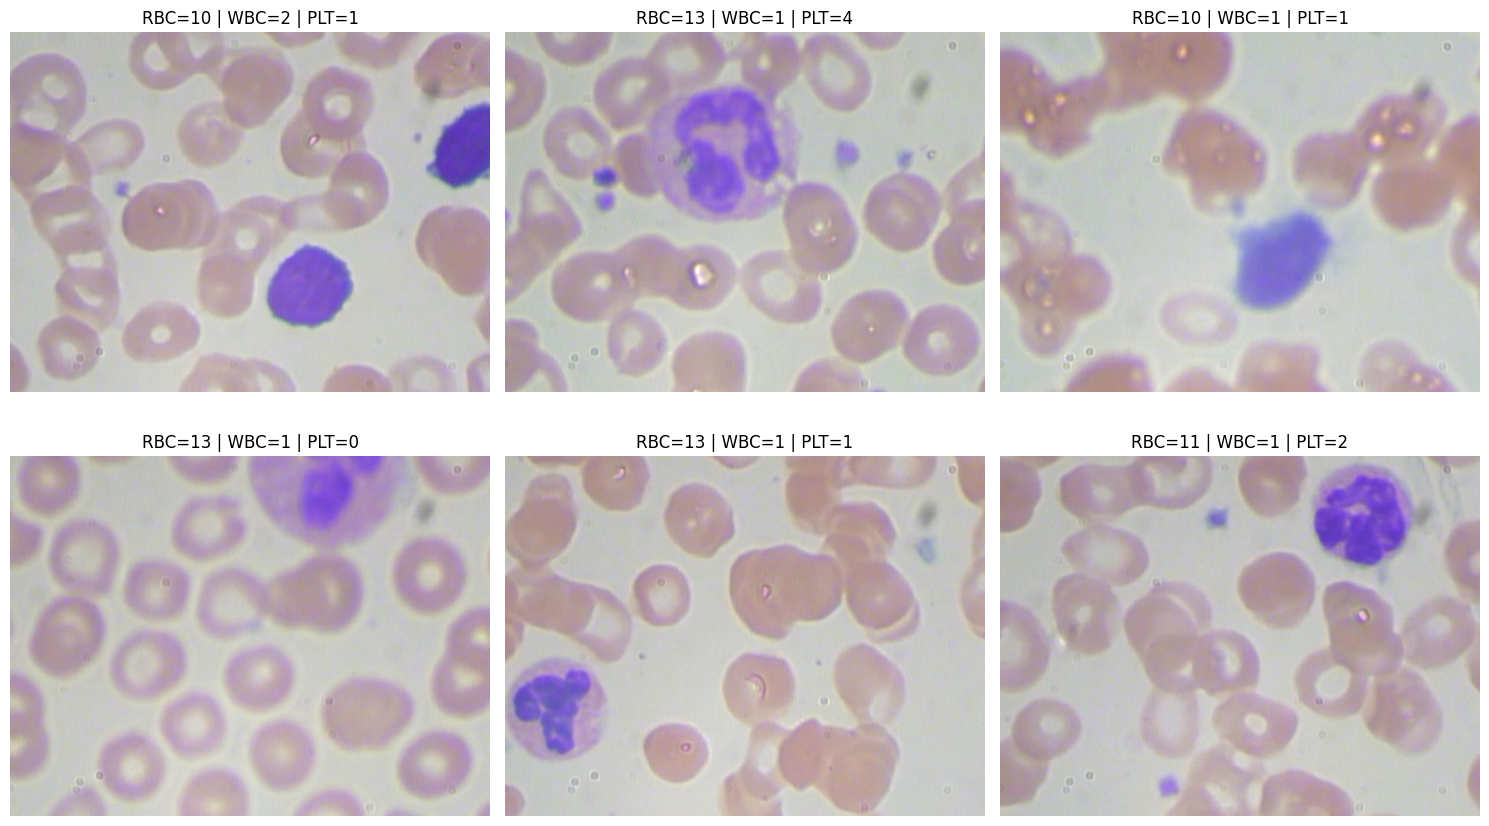

In [9]:
class_cols = ['RBC', 'WBC', 'Platelets']

display(df[class_cols].describe().T)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

totals = df[class_cols].sum()
axes[0].bar(totals.index, totals.values)
axes[0].set_title('Суммарное число объектов по классам')
axes[0].set_ylabel('Количество')

means = df[class_cols].mean()
axes[1].bar(means.index, means.values)
axes[1].set_title('Среднее число объектов на изображение')
axes[1].set_ylabel('Среднее')

corr = df[class_cols].corr()
im = axes[2].imshow(corr.values, vmin=-1, vmax=1)
axes[2].set_xticks(range(len(class_cols)))
axes[2].set_xticklabels(class_cols, rotation=45)
axes[2].set_yticks(range(len(class_cols)))
axes[2].set_yticklabels(class_cols)
axes[2].set_title('Корреляции между классами')

plt.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

sample_df = df.sample(min(6, len(df)), random_state=42)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.ravel()

for ax, (_, row) in zip(axes, sample_df.iterrows()):
    img = cv2.cvtColor(cv2.imread(row['image']), cv2.COLOR_BGR2RGB)
    ax.imshow(img)
    ax.set_title(f"RBC={row['RBC']} | WBC={row['WBC']} | PLT={row['Platelets']}")
    ax.axis('off')

for ax in axes[len(sample_df):]:
    ax.axis('off')

plt.tight_layout()
plt.show()


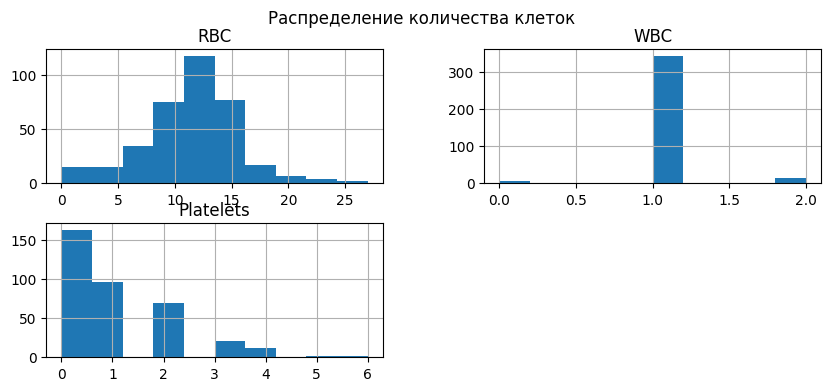

In [10]:

df[['RBC','WBC','Platelets']].hist(figsize=(10,4))
plt.suptitle('Распределение количества клеток')
plt.show()


## Dataset для ResNet50

In [11]:

transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor()
])


In [12]:
class BloodDataset(Dataset):
    def __init__(self, df):
        self.df = df

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image = Image.open(row['image']).convert('RGB')
        image = transform(image)

        target = torch.tensor(
            [row['RBC'], row['WBC'], row['Platelets']],
            dtype=torch.float32
        )

        return image, target


In [13]:
sample_x, sample_y = BloodDataset(df.iloc[[0]])[0]
print('Image tensor shape:', sample_x.shape)
print('Target:', sample_y.tolist())


Image tensor shape: torch.Size([3, 224, 224])
Target: [10.0, 1.0, 1.0]


## Обучение ResNet50

In [14]:

train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)


In [15]:
train_loader = DataLoader(BloodDataset(train_df), batch_size=8, shuffle=True)
test_loader = DataLoader(BloodDataset(test_df), batch_size=8)


In [16]:
model = models.resnet50(weights='DEFAULT')
model.fc = nn.Linear(model.fc.in_features, 3)


In [17]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = model.to(device)


In [18]:
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)


In [19]:
for epoch in range(10):
    model.train()

    total_loss = 0

    for x, y in train_loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()

        pred = model(x)
        loss = criterion(pred, y)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f'Epoch {epoch+1}:', total_loss)


Epoch 1: 1422.797306060791
Epoch 2: 476.55761218070984
Epoch 3: 144.32956063747406
Epoch 4: 103.5083737373352
Epoch 5: 79.57110726833344
Epoch 6: 78.302825152874
Epoch 7: 57.03684550523758
Epoch 8: 54.41749384999275
Epoch 9: 46.934449911117554
Epoch 10: 44.00976499915123


### Диагностика ошибок регрессии


## Оценка регрессии

In [20]:

model.eval()

preds = []
targets = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)

        pred = model(x).cpu().numpy()

        preds.extend(pred)
        targets.extend(y.numpy())


In [21]:
preds = np.array(preds)
targets = np.array(targets)


,MAE,RMSE,R2
Class,,,
RBC,3.494432,4.712294,-0.268456
WBC,0.170462,0.257724,0.005725
Platelets,0.866725,1.192646,0.162247


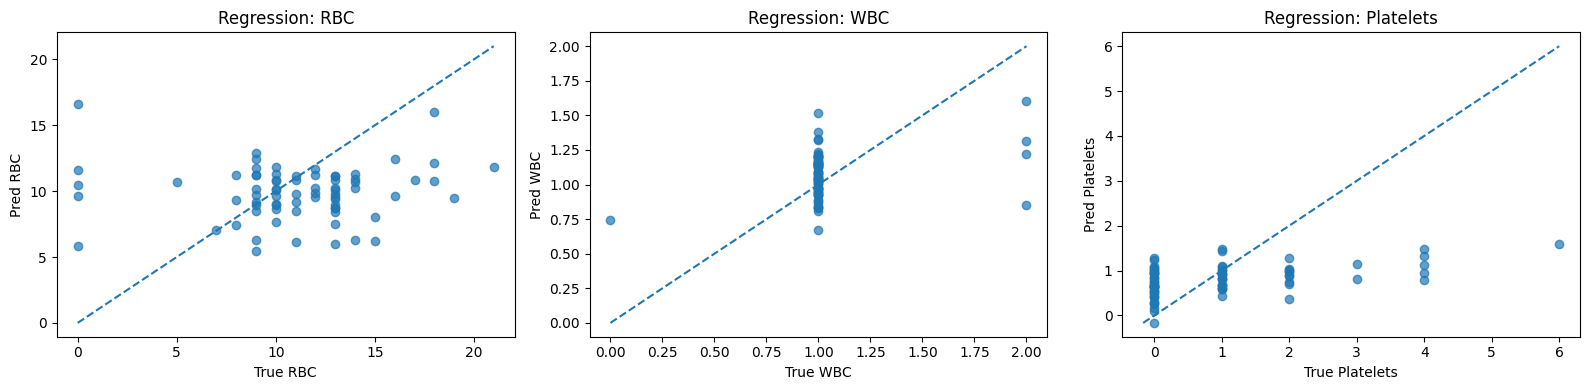

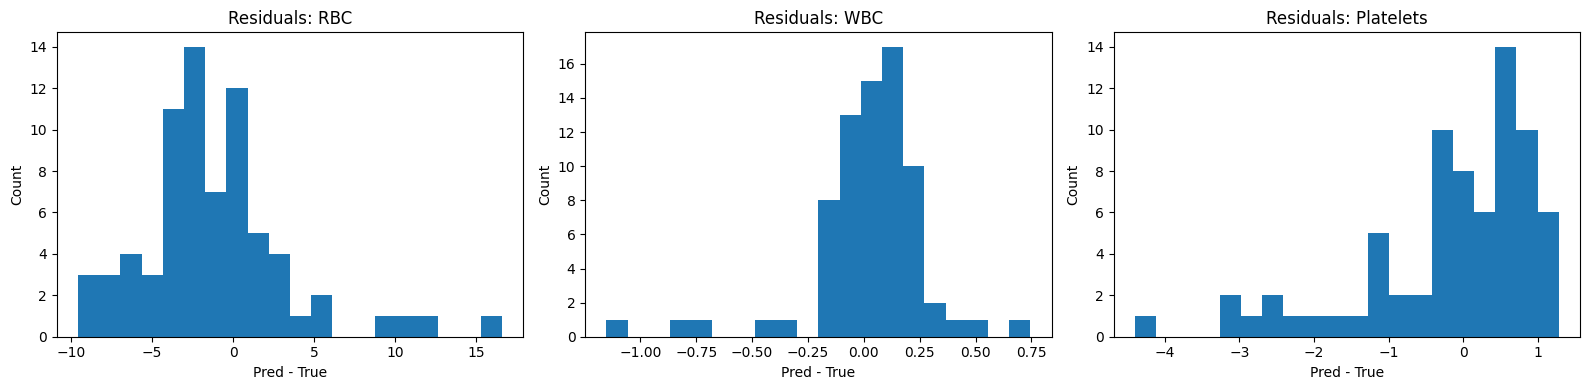

,image,RBC,WBC,Platelets,pred_RBC,pred_WBC,pred_Platelets
0,BCCD_Dataset-master/BCCD/JPEGImages/BloodImage...,10,2,1,9.66,1.22,0.93
1,BCCD_Dataset-master/BCCD/JPEGImages/BloodImage...,13,1,4,9.58,0.92,0.79
2,BCCD_Dataset-master/BCCD/JPEGImages/BloodImage...,10,1,1,7.67,1.38,1.48
3,BCCD_Dataset-master/BCCD/JPEGImages/BloodImage...,13,1,0,7.53,0.97,0.95
4,BCCD_Dataset-master/BCCD/JPEGImages/BloodImage...,13,1,1,11.13,0.92,1.01
5,BCCD_Dataset-master/BCCD/JPEGImages/BloodImage...,11,1,2,9.17,0.95,0.97
6,BCCD_Dataset-master/BCCD/JPEGImages/BloodImage...,5,1,2,10.72,1.32,0.99
7,BCCD_Dataset-master/BCCD/JPEGImages/BloodImage...,14,1,0,10.93,1.01,0.29


In [22]:
class_cols = ['RBC', 'WBC', 'Platelets']
metrics = []

for i, cls in enumerate(class_cols):
    mae = mean_absolute_error(targets[:, i], preds[:, i])
    rmse = np.sqrt(np.mean((targets[:, i] - preds[:, i]) ** 2))
    r2 = r2_score(targets[:, i], preds[:, i])
    metrics.append([cls, mae, rmse, r2])

metrics_df = pd.DataFrame(metrics, columns=['Class', 'MAE', 'RMSE', 'R2']).set_index('Class')
display(metrics_df)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for i, cls in enumerate(class_cols):
    axes[i].scatter(targets[:, i], preds[:, i], alpha=0.7)
    lims = [
        min(targets[:, i].min(), preds[:, i].min()),
        max(targets[:, i].max(), preds[:, i].max())
    ]
    axes[i].plot(lims, lims, '--')
    axes[i].set_xlabel(f'True {cls}')
    axes[i].set_ylabel(f'Pred {cls}')
    axes[i].set_title(f'Regression: {cls}')

plt.tight_layout()
plt.show()

residuals = preds - targets

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for i, cls in enumerate(class_cols):
    axes[i].hist(residuals[:, i], bins=20)
    axes[i].set_title(f'Residuals: {cls}')
    axes[i].set_xlabel('Pred - True')
    axes[i].set_ylabel('Count')

plt.tight_layout()
plt.show()

sample_eval = test_df.iloc[:8].copy().reset_index(drop=True)
sample_eval[['pred_RBC', 'pred_WBC', 'pred_Platelets']] = np.round(preds[:len(sample_eval)], 2)
display(sample_eval[['image', 'RBC', 'WBC', 'Platelets', 'pred_RBC', 'pred_WBC', 'pred_Platelets']])


## YOLO-детекция

In [33]:

model_yolo = YOLO('yolov8n.pt')


In [34]:
model_yolo.train(
    data='blood.yaml',
    epochs=5,
    imgsz=640
)


Ultralytics 8.4.51 🚀 Python-3.13.3 torch-2.11.0 CPU (Apple M3)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=blood.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-8, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0, plots=True, pose=12.0

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x13e7899a0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04804

## Подсчёт клеток через YOLO

In [35]:

results = model_yolo.predict(images[0])

result = results[0]



image 1/1 /Users/maryc/university/PythonProject/инструменты анализа данных/2 sem/3-8 task/BCCD_Dataset-master/BCCD/JPEGImages/BloodImage_00315.jpg: 480x640 19 RBCs, 1 WBC, 24.8ms
Speed: 2.1ms preprocess, 24.8ms inference, 0.3ms postprocess per image at shape (1, 3, 480, 640)


In [36]:
counts = Counter(result.boxes.cls.cpu().numpy())

print('Detected counts:', counts)


Detected counts: Counter({np.float32(0.0): 19, np.float32(1.0): 1})


,MAE,RMSE
Class,,
RBC,11.45,12.917043
WBC,0.10,0.316228
Platelets,1.00,1.581139


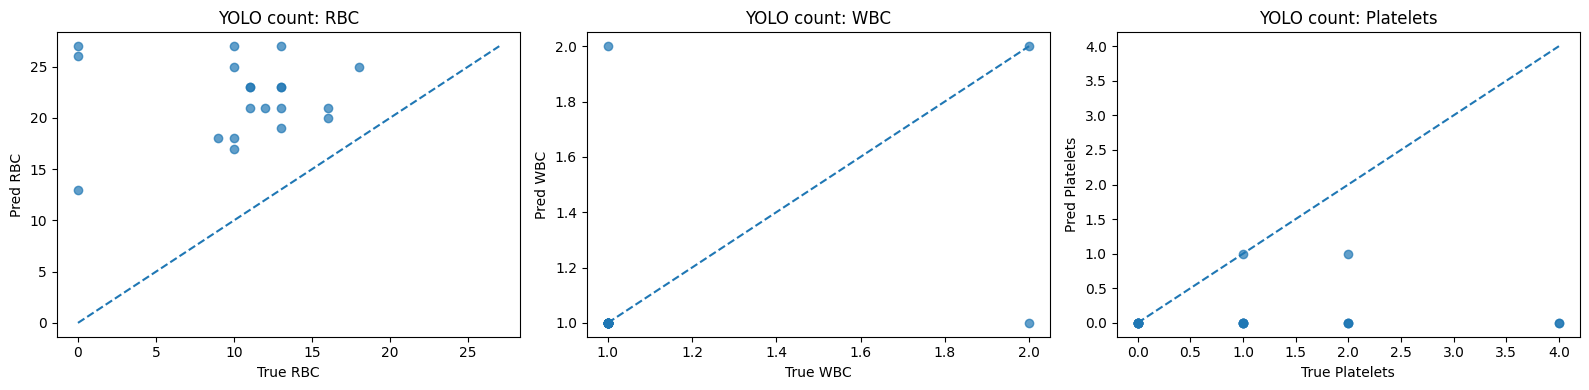

,image,true_RBC,true_WBC,true_Platelets,pred_RBC,pred_WBC,pred_Platelets
0,BCCD_Dataset-master/BCCD/JPEGImages/BloodImage...,13,1,1,21,1,0
1,BCCD_Dataset-master/BCCD/JPEGImages/BloodImage...,13,1,0,19,1,0
2,BCCD_Dataset-master/BCCD/JPEGImages/BloodImage...,13,1,0,27,1,0
3,BCCD_Dataset-master/BCCD/JPEGImages/BloodImage...,10,2,1,27,2,0
4,BCCD_Dataset-master/BCCD/JPEGImages/BloodImage...,0,1,0,26,1,0


In [37]:
class_cols = ['RBC', 'WBC', 'Platelets']

def normalize_class_name(name):
    name = str(name).lower()
    if 'rbc' in name:
        return 'RBC'
    if 'wbc' in name:
        return 'WBC'
    if 'platelet' in name or 'plt' in name:
        return 'Platelets'
    return None

def yolo_count_image(image_path):
    res = model_yolo.predict(image_path, verbose=False)[0]
    pred_counts = {c: 0 for c in class_cols}
    if res.boxes is not None and len(res.boxes) > 0:
        cls_ids = res.boxes.cls.cpu().numpy().astype(int)
        for cls_id in cls_ids:
            cls_name = normalize_class_name(res.names[cls_id])
            if cls_name is not None:
                pred_counts[cls_name] += 1
    return pred_counts

eval_subset = test_df.sample(min(20, len(test_df)), random_state=42).reset_index(drop=True)

yolo_pred_rows = []
for img_path in eval_subset['image']:
    yolo_pred_rows.append(yolo_count_image(img_path))

yolo_pred_df = pd.DataFrame(yolo_pred_rows)
yolo_true_df = eval_subset[class_cols].reset_index(drop=True)

yolo_metrics = []
for cls in class_cols:
    mae = mean_absolute_error(yolo_true_df[cls], yolo_pred_df[cls])
    rmse = np.sqrt(np.mean((yolo_true_df[cls] - yolo_pred_df[cls]) ** 2))
    yolo_metrics.append([cls, mae, rmse])

yolo_metrics_df = pd.DataFrame(yolo_metrics, columns=['Class', 'MAE', 'RMSE']).set_index('Class')
display(yolo_metrics_df)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for i, cls in enumerate(class_cols):
    axes[i].scatter(yolo_true_df[cls], yolo_pred_df[cls], alpha=0.7)
    lims = [
        min(yolo_true_df[cls].min(), yolo_pred_df[cls].min()),
        max(yolo_true_df[cls].max(), yolo_pred_df[cls].max())
    ]
    axes[i].plot(lims, lims, '--')
    axes[i].set_xlabel(f'True {cls}')
    axes[i].set_ylabel(f'Pred {cls}')
    axes[i].set_title(f'YOLO count: {cls}')

plt.tight_layout()
plt.show()

display(pd.concat([eval_subset[['image']], yolo_true_df.add_prefix('true_'), yolo_pred_df.add_prefix('pred_')], axis=1).head())


In [50]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import torch


In [ ]:

def visualize_predictions(image_path, 
                         true_counts, 
                         resnet_preds, 
                         yolo_model,
                         device='cuda' if torch.cuda.is_available() else 'cpu',
                         figsize=(20, 8)):

    # Загрузка изображения
    img_cv = cv2.imread(image_path)
    img_rgb = cv2.cvtColor(img_cv, cv2.COLOR_BGR2RGB)
    img_pil = Image.fromarray(img_rgb)
    
    # YOLO Prediction 
    yolo_results = yolo_model.predict(image_path, verbose=False)[0]
    
    # Копируем изображение для YOLO
    img_yolo = img_rgb.copy()
    
    if yolo_results.boxes is not None and len(yolo_results.boxes) > 0:
        # YOLO 
        img_yolo_plot = yolo_results.plot()  # возвращает numpy array с боксами
        img_yolo_plot = cv2.cvtColor(img_yolo_plot, cv2.COLOR_BGR2RGB)
    else:
        img_yolo_plot = img_yolo.copy()
    
    # ResNet Prediction 
    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor()
    ])
    
    x = transform(img_pil).unsqueeze(0).to(device)
    
    with torch.no_grad():
        resnet_pred = model(x).cpu().numpy()[0]  # model — ваша ResNet модель
    
    resnet_counts = np.round(resnet_pred).astype(int)
    
    # Визуализация 
    fig, axes = plt.subplots(1, 3, figsize=figsize)
    
    # Оригинальное изображение + True counts
    axes[0].imshow(img_rgb)
    axes[0].set_title('Оригинал + True counts', fontsize=14, fontweight='bold')
    axes[0].axis('off')
    
    true_text = f"RBC: {true_counts[0]}\nWBC: {true_counts[1]}\nPlatelets: {true_counts[2]}"
    axes[0].text(10, 30, true_text, fontsize=12, color='white', 
                bbox=dict(facecolor='black', alpha=0.7, boxstyle='round,pad=0.5'))
    
    # YOLO результат
    axes[1].imshow(img_yolo_plot)
    axes[1].set_title('YOLOv8 Detection\n(с bounding boxes)', fontsize=14, fontweight='bold')
    axes[1].axis('off')
    
    # Подсчёт по YOLO
    yolo_counts = {'RBC': 0, 'WBC': 0, 'Platelets': 0}
    if yolo_results.boxes is not None and len(yolo_results.boxes) > 0:
        cls_ids = yolo_results.boxes.cls.cpu().numpy().astype(int)
        for cls_id in cls_ids:
            name = normalize_class_name(yolo_results.names[cls_id])
            if name:
                yolo_counts[name] += 1
    
    yolo_text = f"RBC: {yolo_counts['RBC']}\nWBC: {yolo_counts['WBC']}\nPlatelets: {yolo_counts['Platelets']}"
    axes[1].text(10, 30, yolo_text, fontsize=12, color='lime', 
                bbox=dict(facecolor='black', alpha=0.7, boxstyle='round,pad=0.5'))
    
    # ResNet результат
    axes[2].imshow(img_rgb)
    axes[2].set_title('ResNet50 Regression\n(прямое предсказание)', fontsize=14, fontweight='bold')
    axes[2].axis('off')
    
    resnet_text = f"RBC: {resnet_counts[0]}\nWBC: {resnet_counts[1]}\nPlatelets: {resnet_counts[2]}"
    axes[2].text(10, 30, resnet_text, fontsize=12, color='cyan', 
                bbox=dict(facecolor='black', alpha=0.7, boxstyle='round,pad=0.5'))
    
    # Добавляем сравнение ошибок
    err_rbc = abs(true_counts[0] - resnet_counts[0])
    err_wbc = abs(true_counts[1] - resnet_counts[1])
    err_plt = abs(true_counts[2] - resnet_counts[2])
    
    compare_text = f"Ошибки ResNet:\nRBC: ±{err_rbc} | WBC: ±{err_wbc} | PLT: ±{err_plt}"
    fig.suptitle(f'Сравнение моделей\n{os.path.basename(image_path)}', fontsize=16, fontweight='bold')
    
    plt.tight_layout()
    plt.show()
    
    return yolo_counts, resnet_counts

In [52]:
# Выбираем несколько изображений для демонстрации
sample_images = test_df.sample(6, random_state=42).reset_index(drop=True)


Изображение 1: BloodImage_00112.jpg
True: RBC=13, WBC=1, Platelets=1


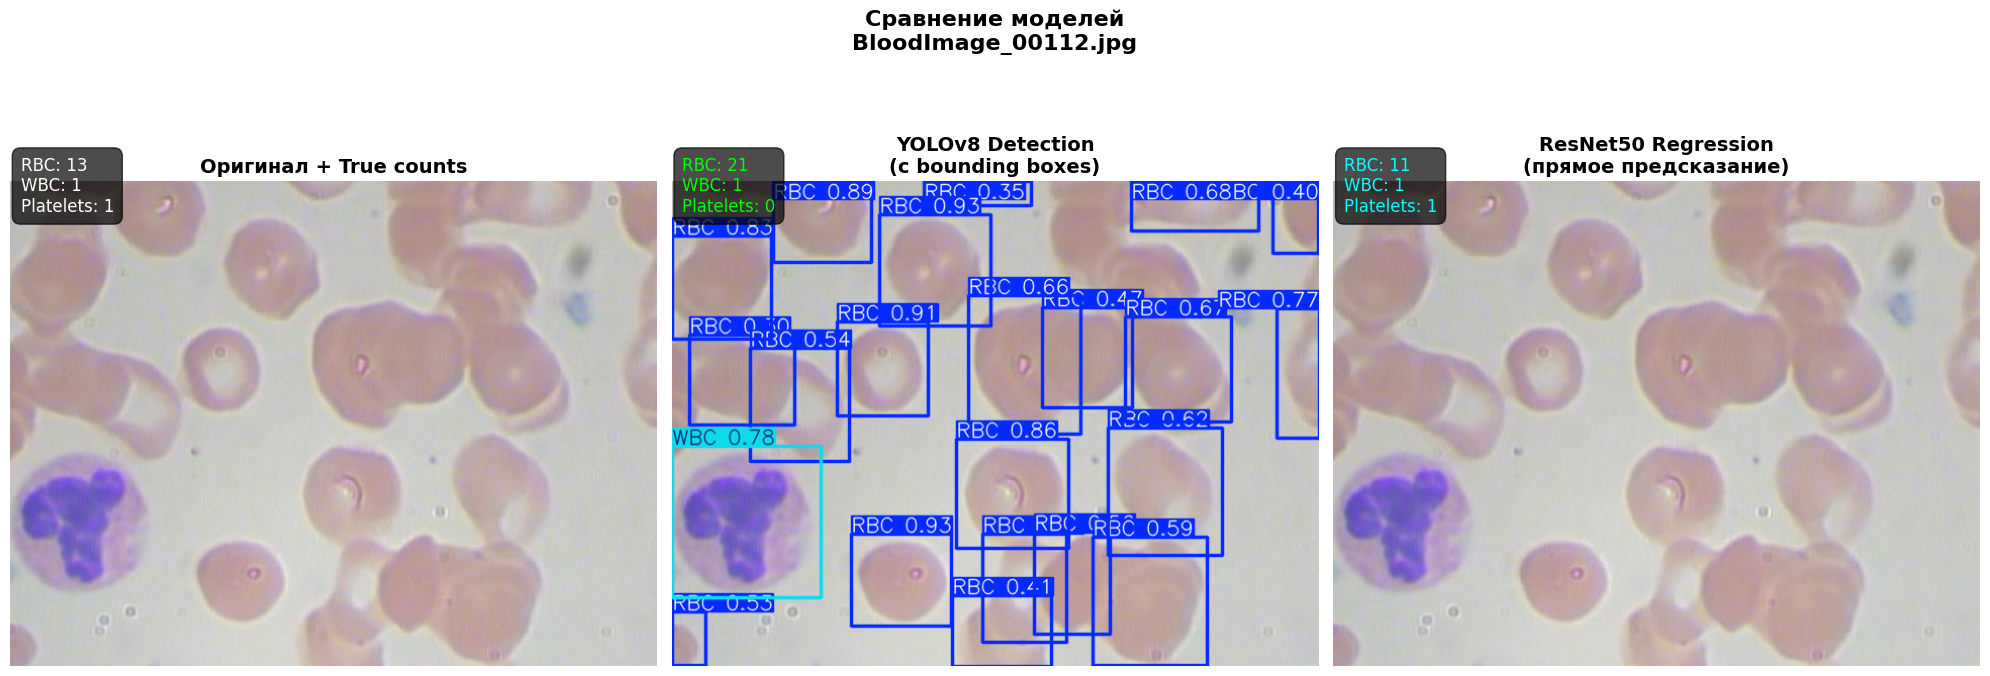


Изображение 2: BloodImage_00272.jpg
True: RBC=13, WBC=1, Platelets=0


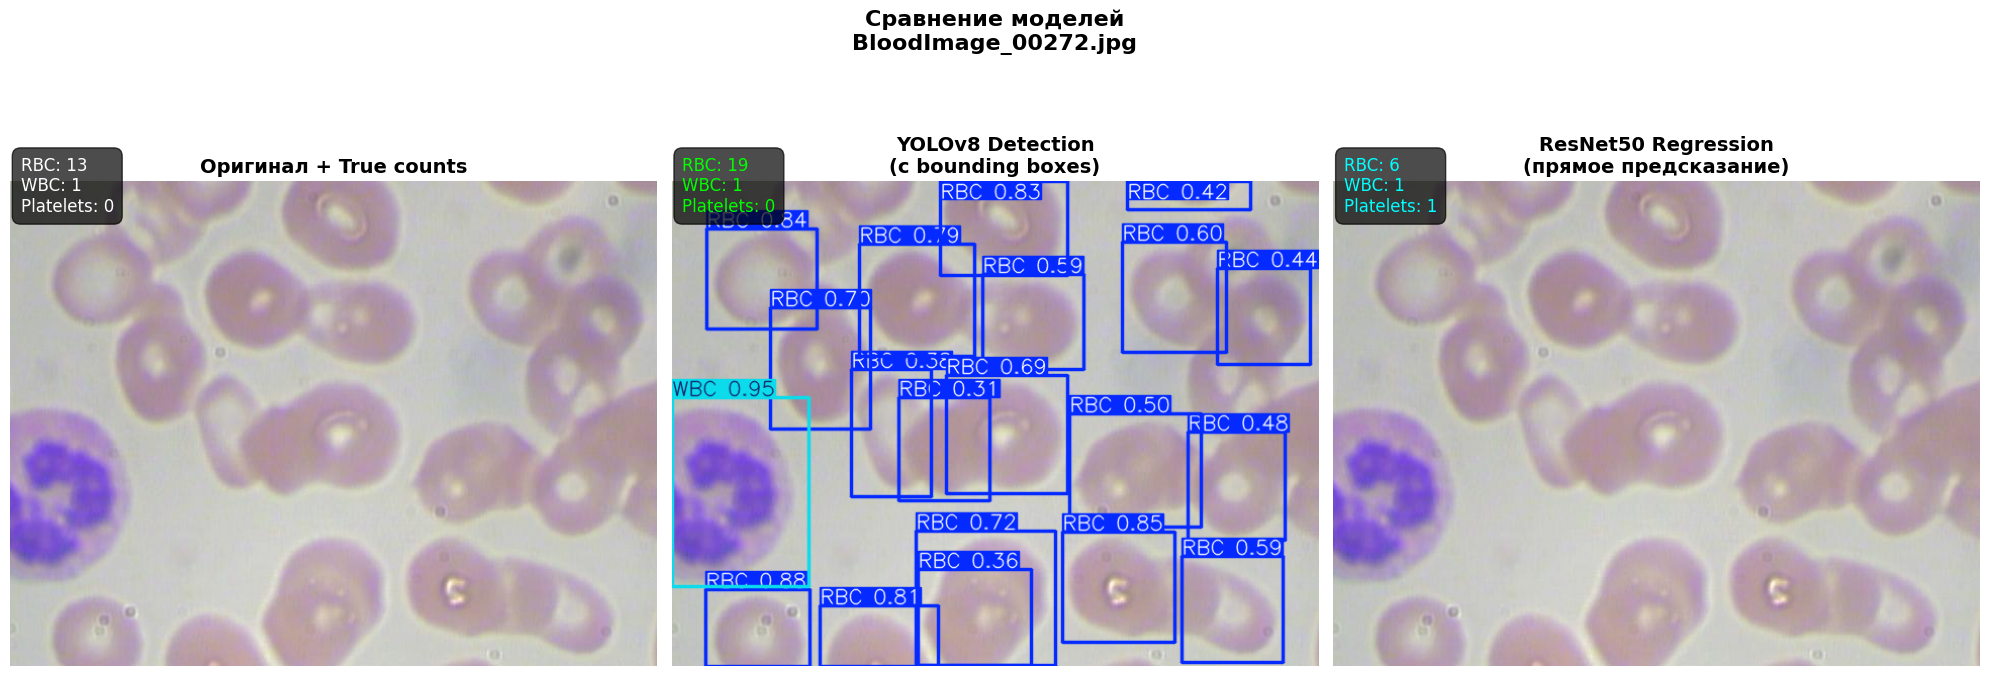


Изображение 3: BloodImage_00247.jpg
True: RBC=13, WBC=1, Platelets=0


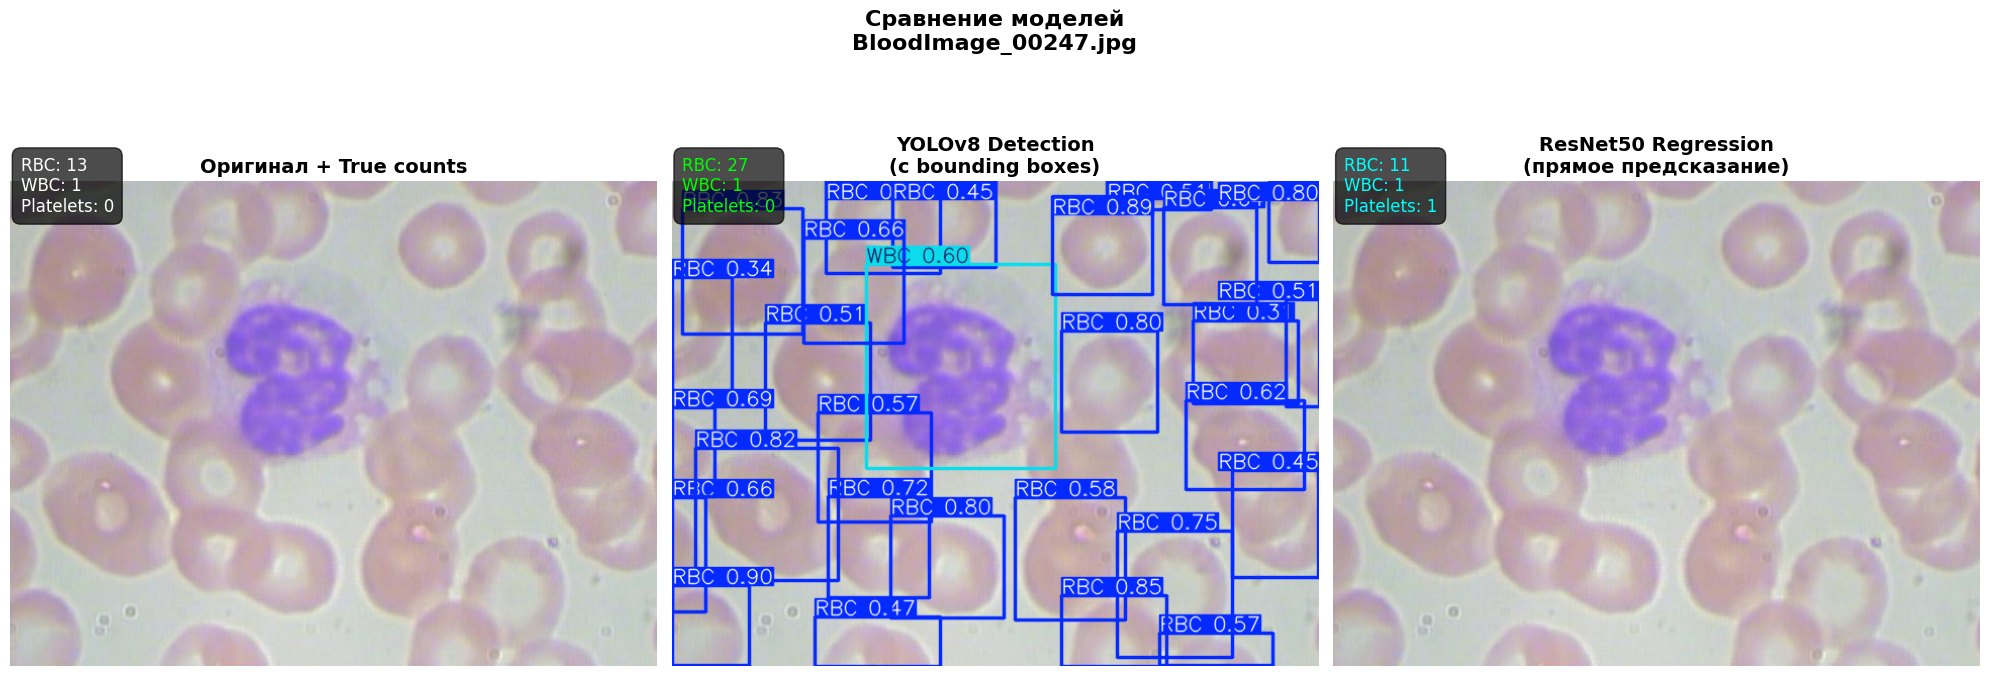


Изображение 4: BloodImage_00195.jpg
True: RBC=10, WBC=2, Platelets=1


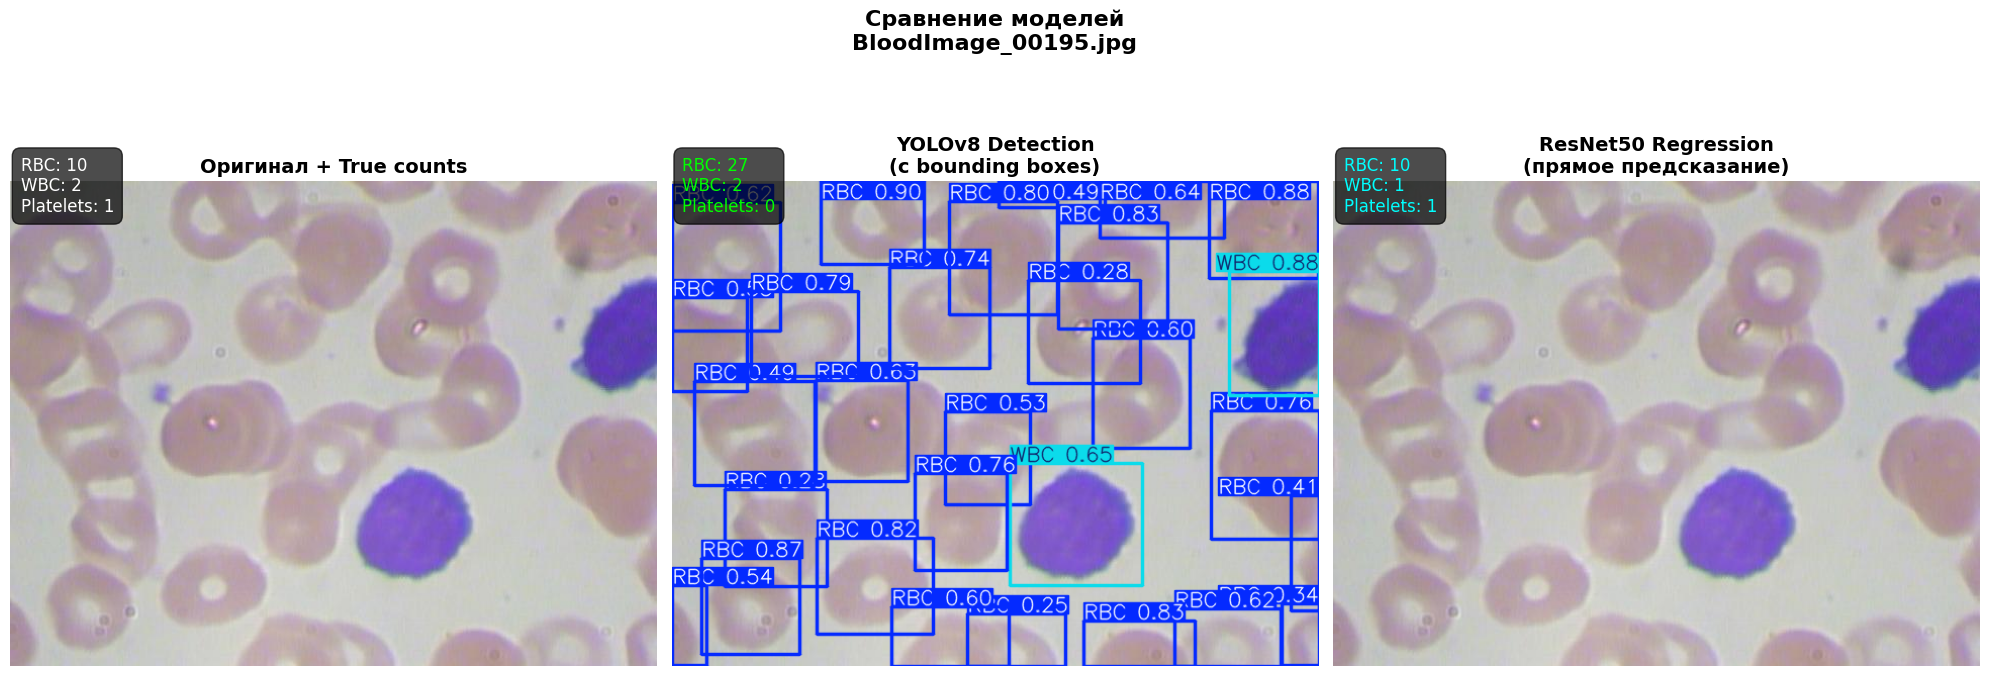


Изображение 5: BloodImage_00330.jpg
True: RBC=0, WBC=1, Platelets=0


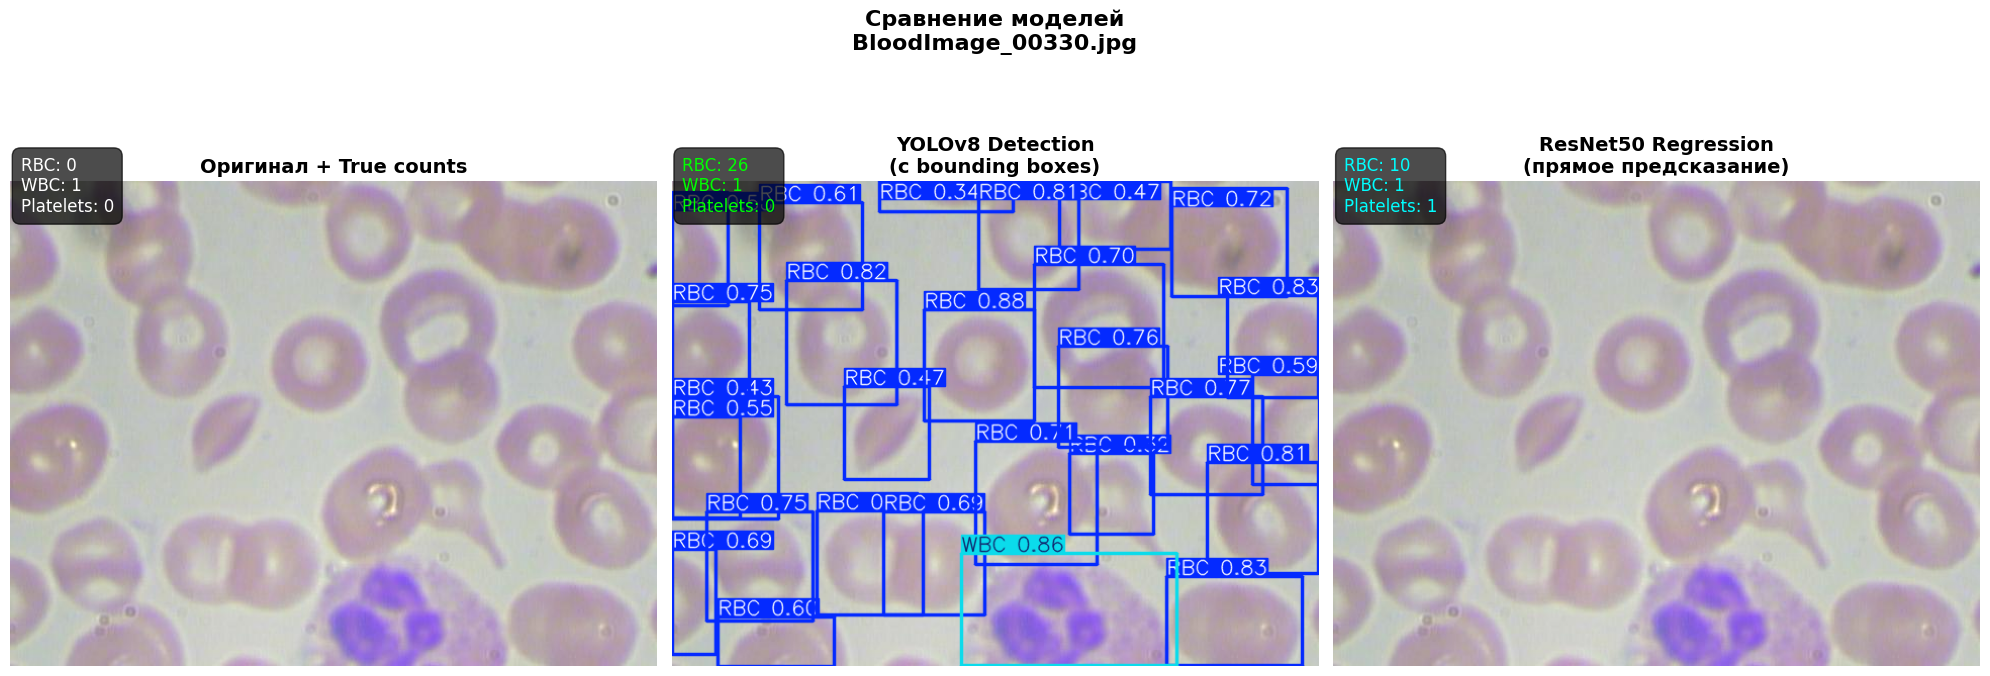


Изображение 6: BloodImage_00068.jpg
True: RBC=9, WBC=1, Platelets=4


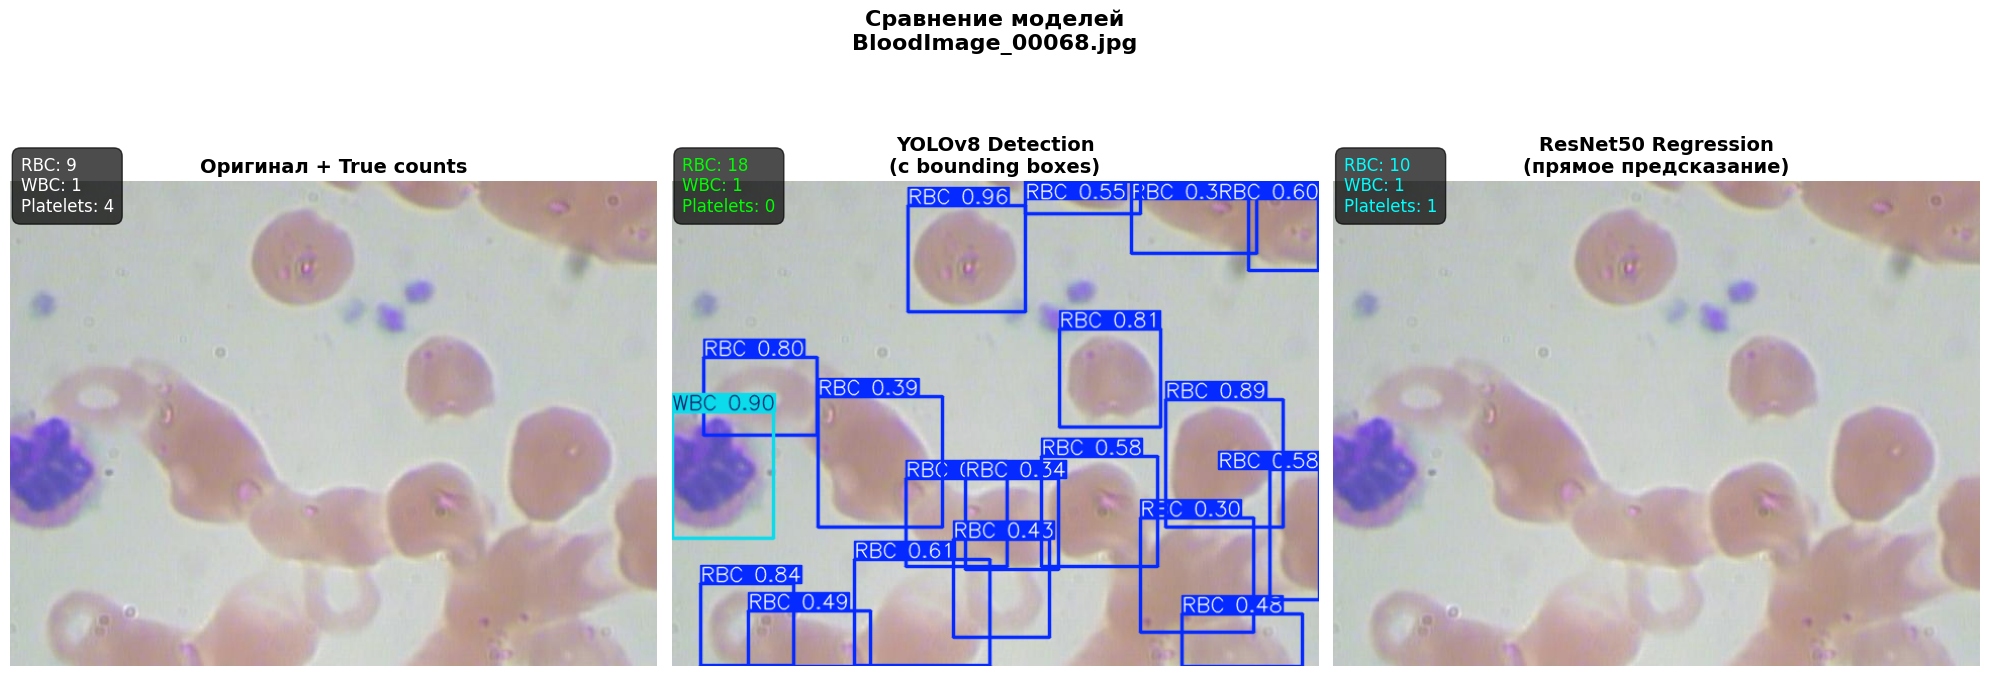

In [53]:
for idx, row in sample_images.iterrows():
    true_counts = [row['RBC'], row['WBC'], row['Platelets']]
    
    print(f"\n{'='*80}")
    print(f"Изображение {idx+1}: {os.path.basename(row['image'])}")
    print(f"True: RBC={true_counts[0]}, WBC={true_counts[1]}, Platelets={true_counts[2]}")
    
    visualize_predictions(
        image_path=row['image'],
        true_counts=true_counts,
        resnet_preds=None,      # не используется внутри функции
        yolo_model=model_yolo,
        device=device
    )

## OOD-детекция

In [28]:

def add_noise(img):
    noise = np.random.normal(0, 25, img.shape)
    noisy = np.clip(img + noise, 0, 255).astype(np.uint8)
    return noisy


In [29]:
def blur(img):
    return cv2.GaussianBlur(img, (11,11), 0)


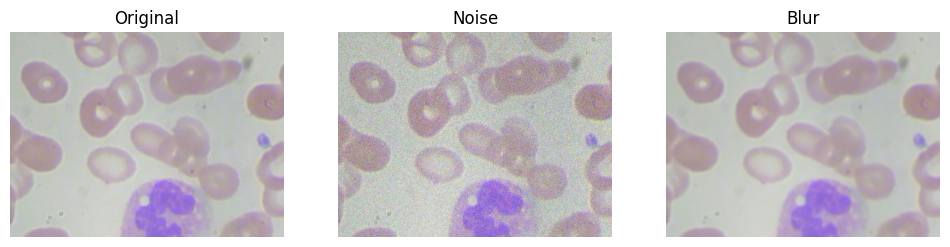

In [30]:
img = cv2.cvtColor(cv2.imread(images[0]), cv2.COLOR_BGR2RGB)

noisy = add_noise(img)
blurred = blur(img)

fig, ax = plt.subplots(1,3, figsize=(12,4))

ax[0].imshow(img)
ax[0].set_title('Original')

ax[1].imshow(noisy)
ax[1].set_title('Noise')

ax[2].imshow(blurred)
ax[2].set_title('Blur')

for a in ax:
    a.axis('off')

plt.show()


### Расширение OOD на более реалистичные изображения

Найдено внешних OOD-изображений: 7


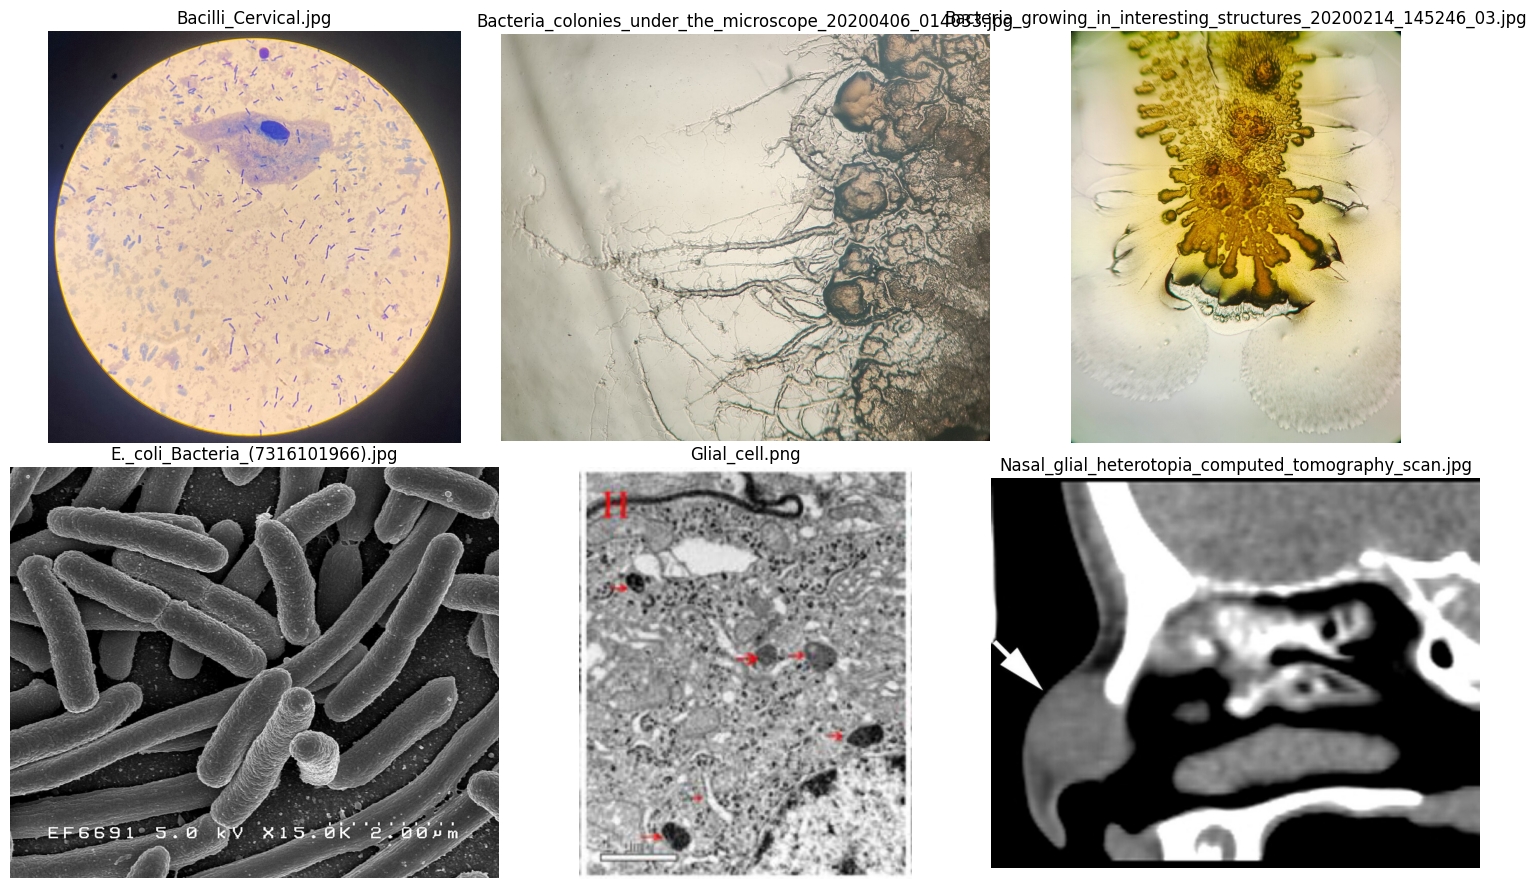

In [46]:
OOD_REAL_DIRS = ['OOD_real']

ood_real_paths = []
for folder in OOD_REAL_DIRS:
    if os.path.isdir(folder):
        for ext in ('*.jpg', '*.jpeg', '*.png', '*.bmp'):
            ood_real_paths.extend(glob.glob(os.path.join(folder, ext)))

ood_real_paths = sorted(set(ood_real_paths))
print('Найдено внешних OOD-изображений:', len(ood_real_paths))

if len(ood_real_paths) > 0:
    sample_ood = ood_real_paths[:6]
    fig, axes = plt.subplots(2, 3, figsize=(15, 9))
    axes = axes.ravel()
    for ax, path_ in zip(axes, sample_ood):
        img = cv2.cvtColor(cv2.imread(path_), cv2.COLOR_BGR2RGB)
        ax.imshow(img)
        ax.set_title(os.path.basename(path_))
        ax.axis('off')
    for ax in axes[len(sample_ood):]:
        ax.axis('off')
    plt.tight_layout()
    plt.show()
else:
    print('Папка с внешними OOD-данными не найдена. Добавьте изображения в одну из указанных папок.')


In [54]:
backbone = nn.Sequential(*list(model.children())[:-1]).to(device)
backbone.eval()

def load_image_array(path, augment=None):
    img = Image.open(path).convert('RGB')
    arr = np.array(img)

    if augment == 'noise':
        arr = add_noise(arr)
    elif augment == 'blur':
        arr = blur(arr)

    return Image.fromarray(arr)

def extract_embeddings(paths, augment=None):
    features = []
    for path_ in paths:
        img = load_image_array(path_, augment=augment)
        x = transform(img).unsqueeze(0).to(device)
        with torch.no_grad():
            feat = backbone(x).flatten(1).cpu().numpy()[0]
        features.append(feat)
    return np.vstack(features)

train_paths = train_df['image'].tolist()
test_paths = test_df['image'].tolist()

train_feat = extract_embeddings(train_paths)
centroid = train_feat.mean(axis=0)

def ood_scores(features):
    return np.linalg.norm(features - centroid, axis=1)

train_scores = ood_scores(train_feat)
clean_scores = ood_scores(extract_embeddings(test_paths))
noise_scores = ood_scores(extract_embeddings(test_paths, augment='noise'))
blur_scores = ood_scores(extract_embeddings(test_paths, augment='blur'))

score_groups = {
    'train (in-distribution)': train_scores,
    'test clean': clean_scores,
    'test noise': noise_scores,
    'test blur': blur_scores,
}

if len(ood_real_paths) > 0:
    real_scores = ood_scores(extract_embeddings(ood_real_paths))
    score_groups['real OOD'] = real_scores

threshold = np.percentile(train_scores, 95)
print('OOD threshold (95th percentile of train scores):', threshold)

for name, scores in score_groups.items():
    rate = (scores > threshold).mean()
    print(f'{name}: mean={scores.mean():.2f}, std={scores.std():.2f}, OOD rate={rate:.2f}')



OOD threshold (95th percentile of train scores): 17.459661
train (in-distribution): mean=11.19, std=5.12, OOD rate=0.05
test clean: mean=9.25, std=2.38, OOD rate=0.01
test noise: mean=12.65, std=2.67, OOD rate=0.05
test blur: mean=9.62, std=2.49, OOD rate=0.01
real OOD: mean=5768.05, std=6067.76, OOD rate=1.00
